In [ ]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

In [ ]:
syn = pd.read_csv(r'......SGA_smote/Synthetic.csv')
syn_df = syn.drop(columns=['A', 'B'], axis=1)
syn_df
list(syn_df.columns)

In [ ]:
real_test_ = pd.read_csv(r'...../Test/SGA_test.csv')
real_test

In [ ]:
real_train_ = pd.read_csv(r'...../Train/SGA_train.csv')
real_train 

# QID columns

In [ ]:
qid_cols = [
    'Race',
    'Birth Weight (grams) ',
    'Total_Gestation_days',
    'Multiple_gestation',
    'null_APGAR Score, 1 Minute ',
    'null_APGAR Score, 5 Minutes ',
    'Location of Birth ',
    'Sex',
    'Inhaled Nitric Oxide ', 
    'PDA Ligation ',
    'Fungal Infection after Day 3 '

    #'Imp_Necrotizing Enterocolitis ' 
]

# Necrotizing Enterocolitis

In [ ]:
attr_nec = 'Necrotizing Enterocolitis '   # change to your attribute name

# Build X (qid) and y (target) fo rsynthetic and real test¶
X_syn = syn_df[qid_cols].copy()
y_syn = syn_df[attr_nec].copy()

X_real = real_test[qid_cols].copy()
y_real = real_test[attr_nec].copy()

# Make y explicitly binary aligned
y_syn = pd.Series(y_syn).astype(int)
y_real = pd.Series(y_real).astype(int)

# Train and evaluate separately
train_mask = y_syn.notna()
X_syn = X_syn.loc[train_mask]
y_syn = y_syn.loc[train_mask]

eval_mask = y_real.notna()
X_real = X_real.loc[eval_mask]
y_real = y_real.loc[eval_mask]

# Split qids into numerical vs categorical columns
num_cols = X_syn.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in qid_cols if c not in num_cols]

#Define preprocessing for mixed qids¶
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preproc = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

# Define attacekr modle Logistic regression
attacker = Pipeline([
    ("preproc", preproc),
    ("clf", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

#Fit attacker model¶
attacker.fit(X_syn, y_syn)

y_pred = attacker.predict(X_real)
y_proba = attacker.predict_proba(X_real)[:, 1]

#Compute AIA metrics (AUROC, Accuracy)
acc = accuracy_score(y_real, y_pred)
auroc = roc_auc_score(y_real, y_proba)

acc, auroc

# Save results in one row 

In [ ]:
result_row = pd.DataFrame([{
    "attribute": attr_nec,
    "attacker_train": "synthetic",
    "attacker_eval": "real_test",
    "model": "logistic_regression",
    "metric_accuracy": float(acc),
    "metric_auroc": float(auroc),
    "n_train": int(len(y_syn)),
    "n_eval": int(len(y_real)),
    "qid_n": int(len(qid_cols)),
    "qid_numeric_n": int(len(num_cols)),
    "qid_categorical_n": int(len(cat_cols)),
}])

result_row


# Baseline comparison: Train on real_train, test on real_test

In [ ]:
X_real_train = real_train[qid_cols].copy()
y_real_train = real_train[attr_nec].copy().astype(int)

train_mask2 = y_real_train.notna()
X_real_train = X_real_train.loc[train_mask2]
y_real_train = y_real_train.loc[train_mask2]


In [ ]:
attacker_real = Pipeline([
    ("preproc", preproc),
    ("clf", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

attacker_real.fit(X_real_train, y_real_train)

y_pred_real = attacker_real.predict(X_real)
y_proba_real = attacker_real.predict_proba(X_real)[:, 1]

acc_real = accuracy_score(y_real, y_pred_real)
auroc_real = roc_auc_score(y_real, y_proba_real)

acc_real, auroc_real


# Compare Synthetic vs Real

In [ ]:
NEC = pd.DataFrame([{
    "attribute": attr_nec,
    "metric": "AUROC",
    "synthetic_trained": float(auroc),
    "real_trained": float(auroc_real),
    "delta_synth_minus_real": float(auroc - auroc_real),
}, 
#                     {
#     "attribute": attr_nec,
#     "metric": "Accuracy",
#     "synthetic_trained": float(acc),
#     "real_trained": float(acc_real),
#     "delta_synth_minus_real": float(acc - acc_real),
# }
                   ])

NEC


## Similarly, AIA was computed for Surgery, Severe IVH, and Sepsis 

# Comparison

In [ ]:
compare_df = pd.concat([NEC, Surgery, Sepsis, IVH])
compare_df

# Plot

In [ ]:
label_map = {
    "Necrotizing Enterocolitis ": "NEC",
    "Other Surgery ": "Surgery",
    "Bacterial Sepsis and/or Meningitis after Day 3 ": "Late-onset Sepsis/Meningitis",
    "Cystic Periventricular Leukomalacia (aka IVH)": "Cystic PVL / Severe IVH",
}
a_df = compare_df[compare_df["metric"] == "AUROC"].copy()
a_df["attribute_label"] = a_df["attribute"].map(label_map)
a_df[["attribute", "attribute_label"]]


In [ ]:
#plot_df = compare_df[compare_df["metric"] == "AUROC"].copy()


# Order the metics
plot_df = a_df.sort_values("delta_synth_minus_real")
plot_df

# Deep, manuscript-safe colors
POINT_COLOR = "#0B2545",# "#163a5f"   # deep blue (clinical, neutral)
ZERO_LINE   = "#6e6e6e"   # muted gray

# Create delta-AUROC plot dot plot
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.scatter(
    plot_df["delta_synth_minus_real"],
    plot_df["attribute_label"],
    s=80
)

# Zero reference line
plt.axvline(0, linestyle="--", linewidth=1.2, color=ZERO_LINE)

# Axis labels
plt.xlabel("Δ AUROC (Synthetic − Real)")
plt.ylabel("Clinically Sensitive Attribute")

# Tight layout for publication
plt.tight_layout()
#plt.savefig("aia_lr_dot_plot.png", dpi=300)
# plt.savefig("aia_lr_dot_plot.pdf", dpi=300)
plt.show()

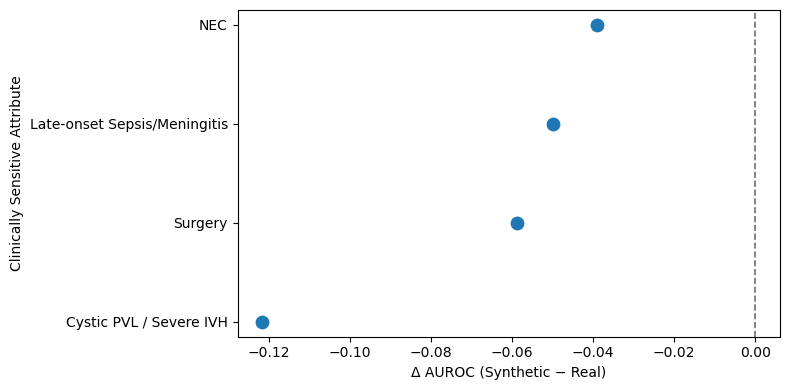